# Part 1: Descriptive Statistics with Python
In this section, we will explore fundamental concepts of quantitative features in rectatuar date.

- Central Tendency: Mean, Median, Mode
- Dispersion: Range, IQR, Variance, STD
- Frequency Tables and Categorical Feature Summaries
- Notion of A Distribution
- Population vs Sample

## 1. Setup & Quick Review
Let's start by importing the necessary libraries and loading a dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# dataset: Titanic (small and real-world)
df = pd.read_csv("https://raw.githubusercontent.com/zuilpirola/DS/refs/heads/main/Week2/titanic.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Exercise 1
- Explore the dataset with `info()`, ` describe()`and check:
  1. How many lines and columns are there?
  2. Which columns are numerical? What are categorical?

In [4]:
df.shape , len(df)

((891, 12), 891)

## 2. Central trend
Let's calculate average, median and mode for some numerical variables.

In [6]:
soma = 0

for item in df['Survived']:
  soma += item

soma / len(df)

0.3838383838383838

In [7]:
df['Survived'].sum() / len(df)

np.float64(0.3838383838383838)

In [8]:
df['Survived'].mean()

np.float64(0.3838383838383838)

In [11]:
counts = {}

for item in df['Survived']:
  if item not in counts:
    counts[item] = 1
  else:
    counts[item] += 1

max(counts, key=counts.get)

0

In [14]:
df.Survived.value_counts()

,count
Survived,
0,549
1,342


In [15]:
df['Survived'].mode()

,Survived
0,0


### Exercise 2
1. Calculate the average, median and mode of the variable `Fare`.
2. Compare with the values obtained for ` Age`.
3. Note the results and discuss: Is there a significant difference between average and median? What can justify this?

In [22]:
def stats_summary(coluna):
  print(f'Mean: {df[coluna].mean()}')
  print(f'Mean: {df[coluna].median()}')
  print(f'Mean: {df[coluna].sum()}')
  print(f'Mean: {df[coluna].min()}')
  print(f'Mean: {df[coluna].max()}')
  print(f'Mean: {df[coluna].mode()[0]}')
  print(f'Mean: {df[coluna].std()}')
  print(f'Mean: {df[coluna].var()}')
  print(f'Mean: {df[coluna].quantile(0.25)}')
  print(f'Mean: {df[coluna].quantile(0.50)}')
  print(f'Mean: {df[coluna].quantile(0.75)}')

stats_summary('Age')

Mean: 29.69911764705882
Mean: 28.0
Mean: 21205.17
Mean: 0.42
Mean: 80.0
Mean: 24.0
Mean: 14.526497332334044
Mean: 211.0191247463081
Mean: 20.125
Mean: 28.0
Mean: 38.0


<Axes: >

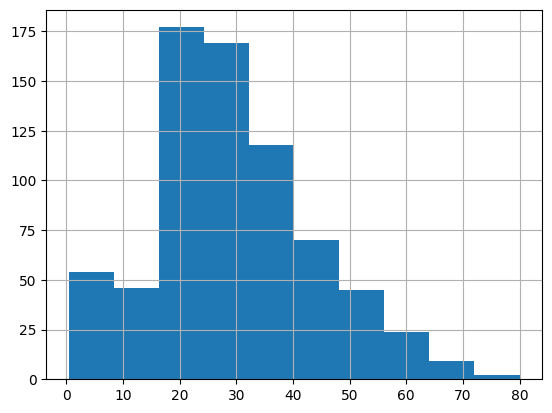

In [23]:
df['Age'].hist()

<Axes: >

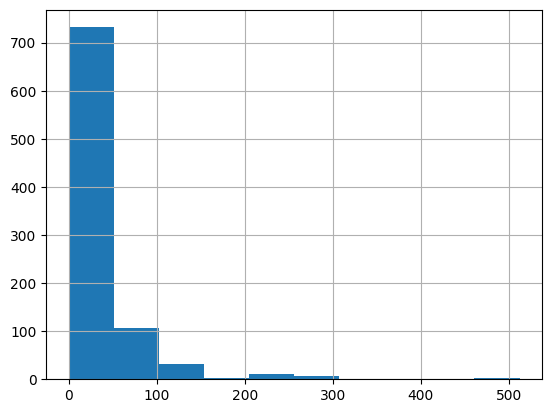

In [24]:
df['Fare'].hist()

## 3. Dispersion measurements
Dispersion measures how spread the data.

In [ ]:
# Example with Age


### Exercise 3
1. Calculate range, iQR, variance and standard deviation for `Fare`.
2. Compare the results of ` Age`and ` Fare`.
3. Make a histogram of each variable. Which has the greatest dispersion?

In [25]:
iqr = df['Fare'].quantile(0.75) - df['Fare'].quantile(0.25)
iqr

np.float64(23.0896)

## 4. Distributions and frequencies
Let's explore distributions with histograms and frequencies for categorical variables.

<Axes: >

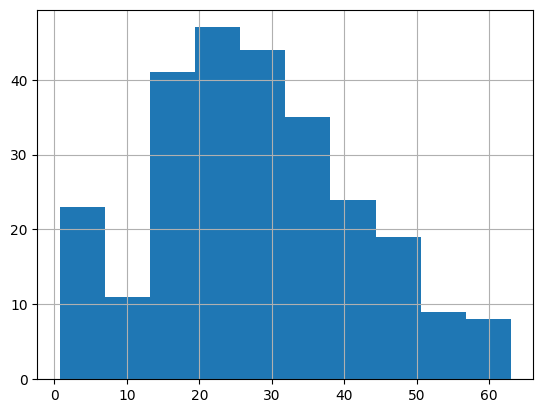

In [29]:
# Age Distribution


# Frequency per gender
df.loc[df.Sex == 'female', 'Age'].hist()

<Axes: >

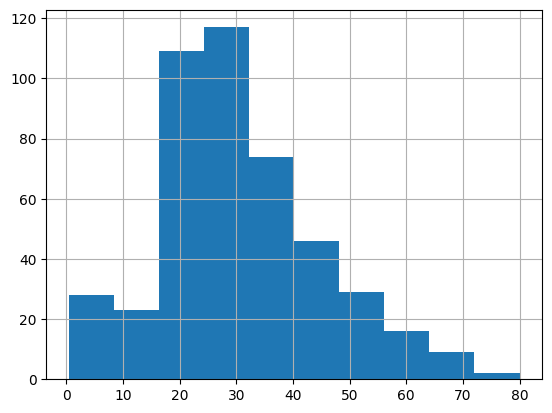

In [28]:
df.loc[df.Sex == 'male', 'Age'].hist()

In [37]:
df.loc[(df.Sex == 'female') & (df['Survived'] == 0), 'Age'].mean()

np.float64(25.046875)

23.818181818181817


<Axes: >

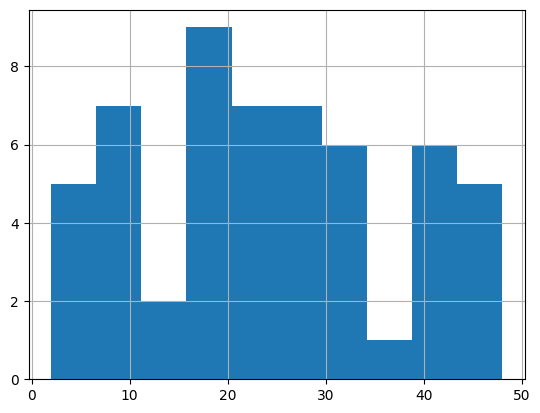

In [38]:
print(df.loc[(df.Sex == 'female') & (df['Survived'] == 0) & (df['Pclass'] == 3), 'Age'].mean())
df.loc[(df.Sex == 'female') & (df['Survived'] == 0) & (df['Pclass'] == 3), 'Age'].hist()

<Axes: >

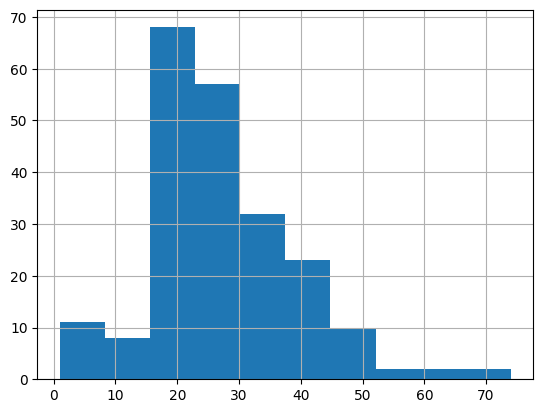

In [39]:
df.loc[(df.Sex == 'male') & (df['Survived'] == 0) & (df['Pclass'] == 3), 'Age'].hist()

### Exercise 4
1. Make a histogram of `Fare`.
2. Create a frequency table for the variable ` Pclass`.
3. Create a Cross Table (CROSSTAB) of ` Sex`X ` Survived`.
4. Calculate the average ` Age` per ` Sex`.


In [40]:
pd.crosstab(df['Sex'], df['Survived'])

Survived,0,1
Sex,,
female,81,233
male,468,109


## 5. Population vs Sample
Let's see how statistics can vary between population and sample.

Média da população (Age): 29.69911764705882
Média da amostra (Age): 30.69382978723404


In [41]:
df.sample(5, random_state=42)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
709,710,1,3,"Moubarek, Master. Halim Gonios (""William George"")",male,NaN,1,1,2661,15.2458,NaN,C
439,440,0,2,"Kvillner, Mr. Johan Henrik Johannesson",male,31.0,0,0,C.A. 18723,10.5000,NaN,S
840,841,0,3,"Alhomaki, Mr. Ilmari Rudolf",male,20.0,0,0,SOTON/O2 3101287,7.9250,NaN,S
720,721,1,2,"Harper, Miss. Annie Jessie ""Nina""",female,6.0,0,1,248727,33.0000,NaN,S
39,40,1,3,"Nicola-Yarred, Miss. Jamila",female,14.0,1,0,2651,11.2417,NaN,C


In [42]:
df['Age'].sample(5).mean()

np.float64(39.7)

### Exercise 5
1. Create a sample of 30% of the data.
2. Compare the average and the standard deviation of `Fare` between the population and this sample.
3. Repeat the process 3 times (with `random_state` different) and note: are the results always the same?

## 6. Mini Reflection
Think and discuss in pairs:
- What really means the variable `Age` On this dataset?
- Are there limitations or contexts that we should keep in mind when analyzing it?

# Part 2: Practical Challenges

In [ ]:
import seaborn as sns

## Exercise 1
Average, median and mode `Fare` and `Age`. Then remove the 5% higher (outliers) and recalculate. What has changed?

In [ ]:
# Average, median and mode
for col in ["Fare", "Age"]:
    print(f"{col}: mean={df[col].mean():.2f}, median={df[col].median():.2f}, mode={df[col].mode()[0]}")

# Remove 5% higher values
df_no_outliers = df[(df["Fare"] <= df["Fare"].quantile(0.95)) & (df["Age"] <= df["Age"].quantile(0.95))]

for col in ["Fare", "Age"]:
    print(f"{col} sem outliers: mean={df_no_outliers[col].mean():.2f}, median={df_no_outliers[col].median():.2f}")

Fare: mean=32.20, median=14.45, mode=8.05
Age: mean=29.70, median=28.00, mode=24.0
Fare sem outliers: mean=24.14, median=13.93
Age sem outliers: mean=27.90, median=28.00


## Exercise 2
Compare the average `Age` between passengers who survived (`Survived=1`) and did not survive.

In [44]:
filter_survived = df['Survived'] == 1

df[filter_survived]['Age'].describe()

,Age
count,290.000000
mean,28.343690
std,14.950952
min,0.420000
25%,19.000000
50%,28.000000
75%,36.000000
max,80.000000


In [45]:
df[-filter_survived]['Age'].describe()

,Age
count,424.000000
mean,30.626179
std,14.172110
min,1.000000
25%,21.000000
50%,28.000000
75%,39.000000
max,74.000000


## Exercise 3
Create a function that is called a numerical column and return Mean, Median, Mode.

In [47]:
def bla(coluna):
  return {
      'mean': float(df[coluna].mean()),
      'median': df[coluna].median(),
      'mode': float(df[coluna].mode()[0])
  }

bla('Fare')

{'mean': 32.204207968574636, 'median': 14.4542, 'mode': 8.05}

## Exercise 4
In what situation is the median better than the average on the Titanic dataset?

## Exercise 5
Calculate range, iQR, variance and standard deviation of `Age` per `Pclass`.


In [59]:
filtros = (df['Pclass'] == 1, df['Pclass'] == 2, df['Pclass'] == 3)
results = []
for i in range(3):
   results.append((df[filtros[i]]['Age'].quantile(0.75) - df[filtros[i]]['Age'].quantile(0.25),
   df[filtros[i]]['Age'].var(),
   df[filtros[i]]['Age'].std()))

print(results)

[(np.float64(22.0), 219.12454269107815, 14.80285589645046), (np.float64(13.0), 196.03015190885873, 14.001076812476201), (np.float64(14.0), 156.13497645102254, 12.495398210982415)]


## Exercise 6
Compare dispersion (STD) of `Fare` and `Sex`.


Sex
female    57.997698
male      43.138263
Name: Fare, dtype: float64

## Exercise 7
Identify the numerical variable with the highest coefficient of variation (STD/Mean).

Parch          2.112344
SibSp          2.108464
Fare           1.543073
Survived       1.267701
PassengerId    0.577027
Age            0.489122
Pclass         0.362149
dtype: float64

## Exercise 8
Compare Boxplots of `Fare` between classes `Pclass`.


## Exercise 9
Plot Histograms of `Age` For each gender.

## Exercise 10
Cross table `Survived` X `Pclass` with line standardization.

Survived,0,1
Pclass,,
1,0.370370,0.629630
2,0.527174,0.472826
3,0.757637,0.242363


## Exercise 11
Distribution of `Embarked` percentage

Embarked
S    0.724409
C    0.188976
Q    0.086614
Name: proportion, dtype: float64

## Exercise 12
Average of `Fare` per `Embarked`


Embarked
C    59.954144
Q    13.276030
S    27.079812
Name: Fare, dtype: float64

## Exercise 13
Proportion of `Sex` within each `Pclass`


Sex,female,male
Pclass,,
1,0.435185,0.564815
2,0.413043,0.586957
3,0.293279,0.706721


## Exercise 14
5 samples of 20% and average `Age` in each

Amostra 1 mean Age: 29.59
Amostra 2 mean Age: 28.04
Amostra 3 mean Age: 29.38
Amostra 4 mean Age: 27.35
Amostra 5 mean Age: 28.46


## Exercise 15
Standard deviation of `Age` for the same samples

Amostra 1 std Age: 14.22
Amostra 2 std Age: 12.96
Amostra 3 std Age: 15.46
Amostra 4 std Age: 13.14
Amostra 5 std Age: 14.29


# Part 3: Reinforcement exercises

This section revisits the descriptive statistics, grouping, frequency tables, visualizations, filters, functions, and sampling techniques used earlier in this notebook. The exercises become gradually more demanding, but they can all be solved by combining methods that have already been introduced.

Continue using the Titanic DataFrame stored in `df`. Read each question carefully and keep intermediate results in clearly named variables.

## R-01 - Central tendency by passenger class

Group the passengers by `Pclass` and calculate the **mean** and **median** of `Fare` for each class. Add a column named `difference` containing the mean minus the median.

Which class shows the largest difference between these two measures? What does this suggest about its fare distribution?

In [ ]:
# Your code and observations here

## R-02 - Age dispersion by survival outcome

For each value of `Survived`, calculate the minimum, maximum, range, IQR, variance, and standard deviation of `Age`.

Compare the two groups. Do they have similar age dispersion?

In [ ]:
# Your code and observations here

## R-03 - Outlier impact within third class

Create a DataFrame containing only third-class passengers. For this group:

1. Calculate the mean and median `Fare`.
2. Find the 95th percentile of `Fare`.
3. Remove fares above that threshold and recalculate the mean and median.
4. Explain which measure changed more and why.

In [ ]:
# Your code and observations here

## R-04 - Survival proportions by sex and class

Create a normalized cross table showing the survival proportions for every combination of `Sex` and `Pclass`.

Each row must sum to 1. Compare the proportion in column `1` (survived) across the groups.

In [ ]:
# Your code and observations here

## R-05 - Relative variability of fares

For each passenger class, calculate the mean and standard deviation of `Fare`. Then calculate the coefficient of variation:

$$CV = \frac{\text{standard deviation}}{\text{mean}}$$

Sort the result from the highest to the lowest coefficient of variation. Which class has the greatest relative variability?

In [ ]:
# Your code and observations here

## R-06 - A reusable descriptive summary

Write a function named `descriptive_summary(data, column)` that returns a dictionary containing:

- count;
- mean;
- median;
- mode;
- range;
- IQR;
- variance;
- standard deviation.

Test it with `Age`, `Fare`, and `Age` for passengers who survived.

In [ ]:
# Your code and observations here

## R-07 - Two views of age and survival

Create both visualizations below:

1. A boxplot comparing `Age` for passengers who survived and did not survive.
2. Overlapping histograms of `Age` for the same two groups, including a legend.

Use the plots together to comment on differences in center, dispersion, and possible outliers.

In [ ]:
# Your code and observations here

## R-08 - Variability between samples

Take five samples containing 20% of the dataset, using `random_state` values from 0 to 4. Store the mean `Fare` from every sample in a list.

Print the five sample means, the population mean, and the range of the sample means (`maximum - minimum`). What does the range tell you?

In [ ]:
# Your code and observations here

## R-09 - Difficult: combined group summary

Group the data by both `Pclass` and `Sex`. Build a DataFrame named `group_summary` containing:

- number of passengers;
- mean age;
- median fare;
- fare standard deviation;
- survival proportion.

Remember that the mean of a column encoded with `0` and `1` is the proportion of records equal to `1`.

In [ ]:
# Your code and observations here

## R-10 - Difficult: interpret the combined summary

Sort `group_summary` from R-09 by `survival_proportion`, from highest to lowest. Then answer:

1. Which group has the highest survival proportion?
2. Which group has the lowest survival proportion?
3. Why should these descriptive results not automatically be interpreted as proof that class or sex *caused* survival?

In [ ]:
# Your code and observations here